# 04 · Bayesian hyperparameter optimisation (Optuna TPE) — LightGBM
The full study (30 trials, 3-fold GroupKFold, objective = CV Top-1) is run by `scripts/04_bayes_opt.py`. Its record is in `results/bayes_opt_trials.csv`.
Below, a **short live study** shows the mechanism, then the full record is loaded.

In [1]:
import os, sys, json, time, warnings
ROOT = os.path.abspath("..")
sys.path.insert(0, os.path.join(ROOT, "src")); sys.path.insert(0, os.path.join(ROOT, "scripts"))
os.chdir(os.path.join(ROOT, "scripts"))  # scripts use paths relative to the repo
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, IFrame, HTML
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
DATA, RES, FIG = os.path.join(ROOT, "data"), os.path.join(ROOT, "results"), os.path.join(ROOT, "results", "figures")

In [2]:
import importlib, optuna, lightgbm as lgb
optuna.logging.set_verbosity(optuna.logging.WARNING)
bo = importlib.import_module("04_bayes_opt")   # loads training data, defines objective + search space
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42, n_startup_trials=3))
t0 = time.time(); study.optimize(bo.objective, n_trials=6); print(f"6 live trials in {time.time()-t0:.0f}s")
display(study.trials_dataframe()[["number", "value", "params_learning_rate", "params_num_leaves", "params_n_estimators", "params_min_child_samples"]].round(4))

6 live trials in 141s


,number,value,params_learning_rate,params_num_leaves,params_n_estimators,params_min_child_samples
0,0,0.9024,0.1725,118,350,75
1,1,0.9039,0.0834,15,550,271
2,2,0.9034,0.0482,50,300,26
3,3,0.9021,0.0133,15,750,183
4,4,0.9032,0.1376,39,500,151
5,5,0.9043,0.0273,72,800,50


## Full search record (30 trials)

best trial: 24 objective 0.9046 (baseline trial 0: 0.9023)


n_estimators         300.000000
learning_rate          0.084177
num_leaves           155.000000
min_child_samples     62.000000
subsample              0.976865
colsample_bytree       0.929211
reg_lambda             0.890623
reg_alpha              0.792920
dtype: float64

,untuned,tuned
cv_macro_f1,0.9380,0.9379
cv_top1,0.9051,0.9070
test_top1,0.9049,0.9065
test_macro_f1,0.9388,0.9385
test_log_loss,0.0874,0.0892
inference_ms_per_1k_obs,40.1091,70.8305


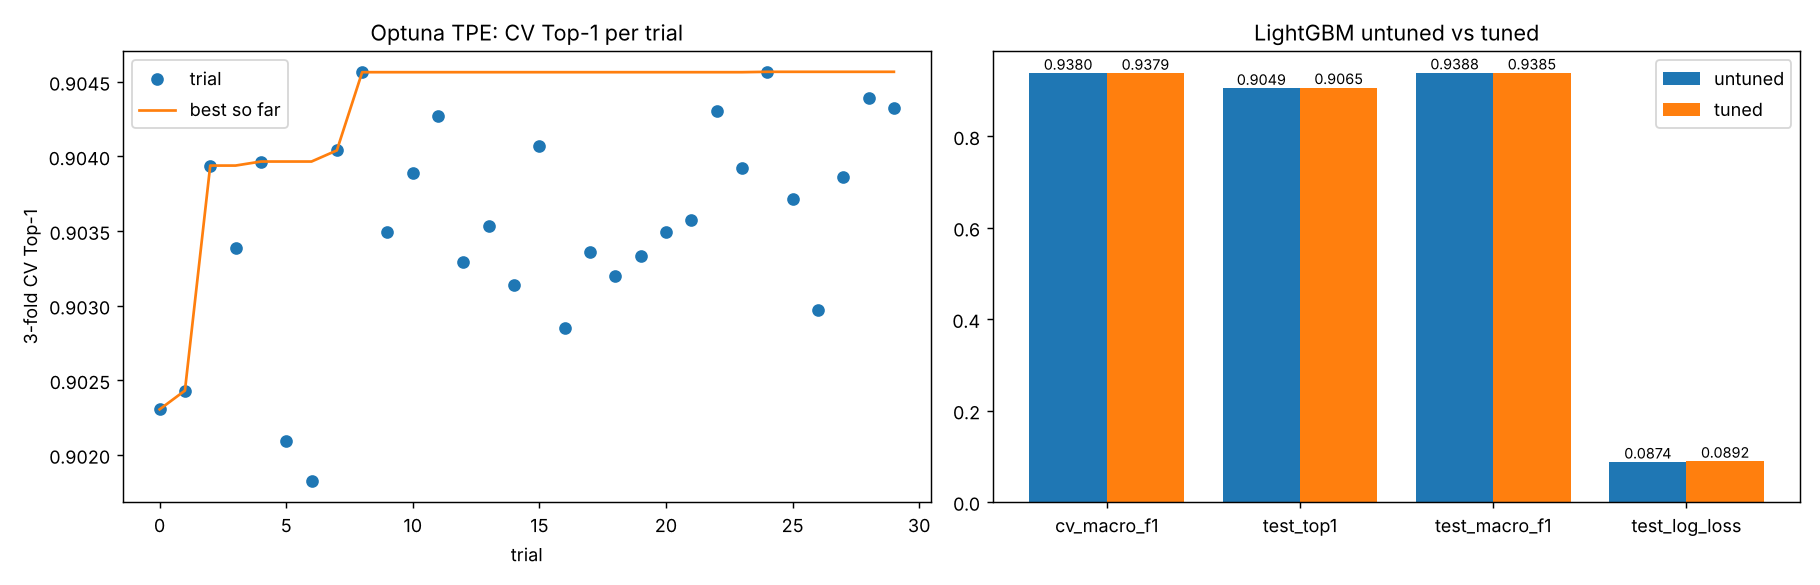

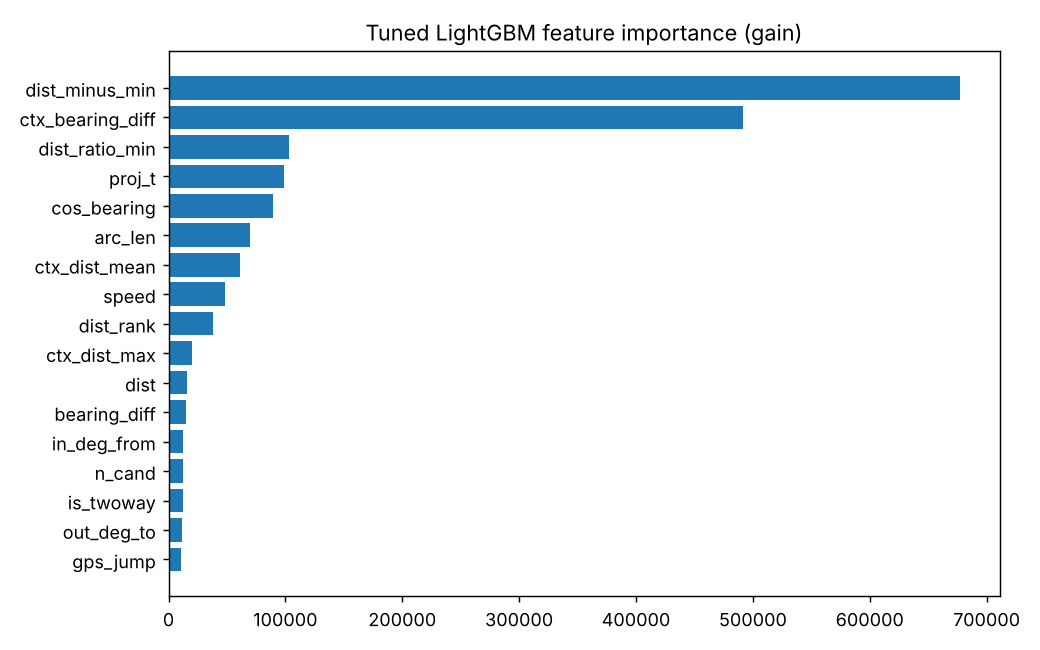

In [3]:
t = pd.read_csv(f"{RES}/bayes_opt_trials.csv"); s = json.load(open(f"{RES}/bayes_opt_summary.json"))
print("best trial:", int(t.value.idxmax()), "objective %.4f (baseline trial 0: %.4f)" % (t.value.max(), t.value.iloc[0]))
display(pd.Series(s["tuned"]["params"]))
cmp = pd.DataFrame({k: {m: s[k][m] for m in ["cv_macro_f1", "cv_top1", "test_top1", "test_macro_f1", "test_log_loss", "inference_ms_per_1k_obs"]} for k in ["untuned", "tuned"]})
display(cmp.round(4))
display(Image(f"{FIG}/bayes_opt.png", width=1000)); display(Image(f"{FIG}/feature_importance.png", width=600))

**Result.** Tuning improved the optimised objective (CV Top-1) by about 0.2 points, and student-test Top-1 by about 0.17 points. Macro F1 was unchanged and log loss slightly worse. The default configuration was already close to what these features allow.